In [ ]:
!pip -q install numpy scipy pandas matplotlib scikit-learn

In [ ]:
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nENVIRONMENT VALIDATION: PASSED")

NumPy: 2.4.6
SciPy: 1.16.3
Pandas: 2.2.3
Scikit-learn: 1.6.1

ENVIRONMENT VALIDATION: PASSED


In [ ]:
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         108G  1.7G  107G   2% /


In [ ]:
import shutil

total, used, free = shutil.disk_usage("/content")

print(f"Total storage: {total / 1e9:.2f} GB")
print(f"Used storage: {used / 1e9:.2f} GB")
print(f"Free storage: {free / 1e9:.2f} GB")

if free < 10 * 1e9:
    raise RuntimeError(
        "Insufficient storage. Do not download the dataset."
    )

print("\nSTORAGE CHECK: PASSED")

Total storage: 115.66 GB
Used storage: 1.82 GB
Free storage: 113.82 GB

STORAGE CHECK: PASSED


In [ ]:
from pathlib import Path

ZIP_PATH = Path("/content/uwb-gestures.zip")

if ZIP_PATH.exists():
    ZIP_PATH.unlink()
    print("Invalid archive deleted.")

print("Ready for a fresh download.")

Invalid archive deleted.
Ready for a fresh download.


In [ ]:

import requests
import zipfile
from pathlib import Path

URL = "https://ssd.mathworks.com/supportfiles/SPT/data/uwb-gestures.zip"

ZIP_PATH = Path("/content/uwb-gestures.zip")
DATA_DIR = Path("/content/uwb_gestures")

print("Connecting to MathWorks dataset server...")

response = requests.get(
    URL,
    stream=True,
    timeout=120,
    headers={"User-Agent": "Mozilla/5.0"}
)

print("HTTP Status:", response.status_code)
print("Content Type:", response.headers.get("Content-Type"))

response.raise_for_status()

first_chunk = next(response.iter_content(chunk_size=1024 * 1024), b"")

if not first_chunk.startswith(b"PK"):
    print("Server response:", first_chunk[:300])
    raise RuntimeError("Server did not return a ZIP archive.")

with open(ZIP_PATH, "wb") as f:
    f.write(first_chunk)

    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            f.write(chunk)

response.close()

print("Download complete!")
print("Size:", round(ZIP_PATH.stat().st_size / 1e9, 2), "GB")

if not zipfile.is_zipfile(ZIP_PATH):
    ZIP_PATH.unlink(missing_ok=True)
    raise RuntimeError("Invalid ZIP archive.")

with zipfile.ZipFile(ZIP_PATH) as zf:

    integrity = zf.testzip()

    if integrity is not None:
        raise RuntimeError(f"Corrupted file: {integrity}")

    print("ZIP integrity: PASSED")

    zf.extractall(DATA_DIR)

print("\nDATASET DOWNLOAD AND EXTRACTION SUCCESSFUL!")


Connecting to MathWorks dataset server...
HTTP Status: 200
Content Type: application/zip
Download complete!
Size: 3.68 GB
ZIP integrity: PASSED

DATASET DOWNLOAD AND EXTRACTION SUCCESSFUL!


In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/uwb_gestures")

mat_files = sorted(DATA_DIR.rglob("*.mat"))

print("Total MAT files:", len(mat_files))

for file in mat_files[:10]:
    print(file.name)

Total MAT files: 96
HV_01_G10_RawData.mat
HV_01_G11_RawData.mat
HV_01_G12_RawData.mat
HV_01_G1_RawData.mat
HV_01_G2_RawData.mat
HV_01_G3_RawData.mat
HV_01_G4_RawData.mat
HV_01_G5_RawData.mat
HV_01_G6_RawData.mat
HV_01_G7_RawData.mat


In [ ]:

from scipy.io import loadmat
from pathlib import Path
import numpy as np
import re

DATA_DIR = Path("/content/uwb_gestures")
mat_files = sorted(DATA_DIR.rglob("*.mat"))

subjects = set()
gestures = set()
errors = []

channel_counts = {
    "Left": 0,
    "Top": 0,
    "Right": 0
}

for path in mat_files:

    match = re.search(
        r"HV_(\d+)_G(\d+)_RawData\.mat$",
        path.name,
        re.IGNORECASE
    )

    if not match:
        errors.append(f"Invalid filename: {path.name}")
        continue

    subject = int(match.group(1))
    gesture = int(match.group(2))

    subjects.add(subject)
    gestures.add(gesture)

    try:
        mat = loadmat(path)

        for channel in channel_counts:

            if channel not in mat:
                errors.append(f"Missing {channel}: {path.name}")
                continue

            array = mat[channel]

            if array.shape != (9000, 189):
                errors.append(
                    f"Wrong shape: {path.name}, "
                    f"{channel}, {array.shape}"
                )
                continue

            if not np.isfinite(array).all():
                errors.append(
                    f"Invalid values: {path.name}, {channel}"
                )
                continue

            channel_counts[channel] += 1

    except Exception as exc:
        errors.append(f"{path.name}: {exc}")

print("=" * 50)
print("UWB GESTURES DATASET VALIDATION")
print("=" * 50)

print("Total MAT files:", len(mat_files))
print("Participants:", sorted(subjects))
print("Gesture classes:", sorted(gestures))
print("Channel validation:", channel_counts)
print("Total errors:", len(errors))

if errors:
    print("\nFirst errors:")
    for error in errors[:20]:
        print(error)

    raise RuntimeError("VALIDATION FAILED")

assert len(mat_files) == 96
assert len(subjects) == 8
assert gestures == set(range(1, 13))
assert all(v == 96 for v in channel_counts.values())

print("\nDATASET VALIDATION: PASSED")


UWB GESTURES DATASET VALIDATION
Total MAT files: 96
Participants: [1, 2, 3, 4, 5, 6, 7, 8]
Gesture classes: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Channel validation: {'Left': 95, 'Top': 95, 'Right': 95}
Total errors: 3

First errors:
Wrong shape: HV_06_G4_RawData.mat, Left, (8370, 189)
Wrong shape: HV_06_G4_RawData.mat, Top, (8370, 189)
Wrong shape: HV_06_G4_RawData.mat, Right, (8370, 189)


RuntimeError: VALIDATION FAILED

In [ ]:
from scipy.io import loadmat
import numpy as np

file_path = DATA_DIR / "HV_06" / "HV_06_G4_RawData.mat"

# Locate file automatically if folder structure differs
if not file_path.exists():
    matches = list(DATA_DIR.rglob("HV_06_G4_RawData.mat"))
    if not matches:
        raise FileNotFoundError("Exceptional MAT file not found.")
    file_path = matches[0]

mat = loadmat(file_path)

print("FILE:", file_path.name)

for channel in ["Left", "Top", "Right"]:
    data = mat[channel]

    print(f"\n{channel} channel")
    print("Shape:", data.shape)
    print("Frames:", data.shape[0])
    print("Range bins:", data.shape[1])
    print("Complete recordings:", data.shape[0] // 90)
    print("Remaining frames:", data.shape[0] % 90)
    print("Finite values:", np.isfinite(data).all())

FILE: HV_06_G4_RawData.mat

Left channel
Shape: (8370, 189)
Frames: 8370
Range bins: 189
Complete recordings: 93
Remaining frames: 0
Finite values: True

Top channel
Shape: (8370, 189)
Frames: 8370
Range bins: 189
Complete recordings: 93
Remaining frames: 0
Finite values: True

Right channel
Shape: (8370, 189)
Frames: 8370
Range bins: 189
Complete recordings: 93
Remaining frames: 0
Finite values: True


In [ ]:

from scipy.io import loadmat
from pathlib import Path
import numpy as np
import re
import pandas as pd

DATA_DIR = Path("/content/uwb_gestures")
mat_files = sorted(DATA_DIR.rglob("*.mat"))

subjects = set()
gestures = set()
errors = []
records = []

for path in mat_files:

    match = re.search(
        r"HV_(\d+)_G(\d+)_RawData\.mat$",
        path.name,
        re.IGNORECASE
    )

    if not match:
        errors.append(f"Invalid filename: {path.name}")
        continue

    subject = int(match.group(1))
    gesture = int(match.group(2))

    subjects.add(subject)
    gestures.add(gesture)

    try:
        mat = loadmat(path)

        shapes = {}
        valid = True

        for channel in ["Left", "Top", "Right"]:

            if channel not in mat:
                errors.append(f"{path.name}: Missing {channel}")
                valid = False
                continue

            array = mat[channel]

            if array.ndim != 2 or array.shape[1] != 189:
                errors.append(
                    f"{path.name}: Invalid {channel} shape "
                    f"{array.shape}"
                )
                valid = False
                continue

            if array.shape[0] == 0 or array.shape[0] % 90 != 0:
                errors.append(
                    f"{path.name}: Invalid frame count "
                    f"{array.shape[0]}"
                )
                valid = False
                continue

            if not np.isfinite(array).all():
                errors.append(
                    f"{path.name}: Non-finite {channel} values"
                )
                valid = False
                continue

            shapes[channel] = array.shape

        if not valid:
            continue

        if len(set(shapes.values())) != 1:
            errors.append(
                f"{path.name}: Channel shape mismatch {shapes}"
            )
            continue

        rows = shapes["Left"][0]
        recording_count = rows // 90

        records.append({
            "file": path.name,
            "subject": subject,
            "gesture": gesture,
            "rows": rows,
            "recordings": recording_count,
            "channels": 3,
            "status": (
                "STANDARD" if recording_count == 100
                else "DEVIATION"
            )
        })

    except Exception as exc:
        errors.append(f"{path.name}: {exc}")

df = pd.DataFrame(records)

print("=" * 55)
print("UWB GESTURES DATASET VALIDATION")
print("=" * 55)

print("Files discovered:", len(mat_files))
print("Files validated:", len(df))
print("Participants:", sorted(subjects))
print("Gesture classes:", sorted(gestures))
print("Validation errors:", len(errors))

if len(df):
    print("\nRecording count distribution:")
    print(df["recordings"].value_counts().sort_index())

    print("\nFiles deviating from standard:")
    print(
        df[df["recordings"] != 100][
            ["file", "rows", "recordings", "status"]
        ].to_string(index=False)
    )

    print("\nTotal actual recordings:", df["recordings"].sum())

if errors:
    print("\nERRORS:")
    for error in errors[:20]:
        print(error)

if (
    len(df) != 96
    or len(subjects) != 8
    or gestures != set(range(1, 13))
    or errors
):
    raise RuntimeError("DATASET STRUCTURAL VALIDATION FAILED")

print("\nSTRUCTURAL VALIDATION: PASSED")
print("Recording-count deviations:", (df["recordings"] != 100).sum())


UWB GESTURES DATASET VALIDATION
Files discovered: 96
Files validated: 96
Participants: [1, 2, 3, 4, 5, 6, 7, 8]
Gesture classes: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Validation errors: 0

Recording count distribution:
recordings
93      1
100    95
Name: count, dtype: int64

Files deviating from standard:
                file  rows  recordings    status
HV_06_G4_RawData.mat  8370          93 DEVIATION

Total actual recordings: 9593

STRUCTURAL VALIDATION: PASSED
Recording-count deviations: 1


In [ ]:
df.to_csv(
    "/content/uwb_dataset_inventory.csv",
    index=False
)

print("Dataset inventory saved.")
print("Total recordings:", df["recordings"].sum())

Dataset inventory saved.
Total recordings: 9593


In [ ]:
from pathlib import Path
import zipfile
import hashlib

ZIP_PATH = Path("/content/uwb-gestures.zip")

matches = list(DATA_DIR.rglob("HV_06_G4_RawData.mat"))

if len(matches) != 1:
    raise RuntimeError(f"Expected one matching file, found {len(matches)}")

mat_path = matches[0]

def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

# Hash the extracted file
with open(mat_path, "rb") as f:
    extracted_hash = sha256_bytes(f.read())

# Find and hash the same file inside the original ZIP
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zip_matches = [
        name for name in zf.namelist()
        if name.endswith("HV_06_G4_RawData.mat")
    ]

    if len(zip_matches) != 1:
        raise RuntimeError(
            f"Expected one ZIP entry, found {len(zip_matches)}"
        )

    original_bytes = zf.read(zip_matches[0])
    original_hash = sha256_bytes(original_bytes)

print("Extracted file:", extracted_hash)
print("Original ZIP:  ", original_hash)

if extracted_hash == original_hash:
    print("\nRESULT: FILE MATCHES ORIGINAL ZIP.")
    print("The unusual recording count is present in the downloaded archive.")
else:
    print("\nRESULT: HASH MISMATCH.")
    print("We need to investigate the extraction.")

Extracted file: 6be8df613aeaba03aed02935ca3090be3f708ba5b940cd2ec7822e3f53a0d3d4
Original ZIP:   6be8df613aeaba03aed02935ca3090be3f708ba5b940cd2ec7822e3f53a0d3d4

RESULT: FILE MATCHES ORIGINAL ZIP.
The unusual recording count is present in the downloaded archive.


In [ ]:
import numpy as np
import pandas as pd
import re
from pathlib import Path
from scipy.io import loadmat

# Configuration
CHANNELS = ["Left", "Top", "Right"]
FRAMES_PER_RECORDING = 90
RANGE_BINS = 189

OUTPUT_DIR = Path("/content/uwb_processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Find all MAT files
mat_files = sorted(DATA_DIR.rglob("*.mat"))

# Calculate total recordings from validated inventory
total_recordings = int(df["recordings"].sum())

print("Total MAT files:", len(mat_files))
print("Total recordings:", total_recordings)

# Create disk-backed array
X = np.lib.format.open_memmap(
    OUTPUT_DIR / "X_recordings.npy",
    mode="w+",
    dtype=np.float32,
    shape=(
        total_recordings,
        FRAMES_PER_RECORDING,
        RANGE_BINS,
        len(CHANNELS)
    )
)

metadata = []
recording_pointer = 0

# Process each MAT file
for file_index, file_path in enumerate(mat_files):

    match = re.search(
        r"HV_(\d+)_G(\d+)_RawData\.mat",
        file_path.name
    )

    if match is None:
        raise ValueError(f"Unexpected filename: {file_path.name}")

    participant_id = int(match.group(1))
    gesture_id = int(match.group(2))

    mat = loadmat(file_path)

    channel_data = {}

    for channel in CHANNELS:

        if channel not in mat:
            raise KeyError(
                f"{channel} missing in {file_path.name}"
            )

        data = np.asarray(mat[channel])

        if data.shape[1] != RANGE_BINS:
            raise ValueError(
                f"Unexpected shape in {file_path.name}: {data.shape}"
            )

        if not np.isfinite(data).all():
            raise ValueError(
                f"Non-finite values in {file_path.name}, {channel}"
            )

        channel_data[channel] = data

    # Ensure all three channels have identical shapes
    shapes = [channel_data[c].shape for c in CHANNELS]

    if len(set(shapes)) != 1:
        raise ValueError(
            f"Channel shape mismatch in {file_path.name}: {shapes}"
        )

    number_of_recordings = (
        channel_data["Left"].shape[0] // FRAMES_PER_RECORDING
    )

    if channel_data["Left"].shape[0] % FRAMES_PER_RECORDING != 0:
        raise ValueError(
            f"Incomplete recording in {file_path.name}"
        )

    # Reshape and combine channels
    reshaped_channels = []

    for channel in CHANNELS:

        channel_array = channel_data[channel].reshape(
            number_of_recordings,
            FRAMES_PER_RECORDING,
            RANGE_BINS
        )

        reshaped_channels.append(channel_array)

    combined = np.stack(
        reshaped_channels,
        axis=-1
    ).astype(np.float32)

    start = recording_pointer
    end = start + number_of_recordings

    X[start:end] = combined

    # Generate metadata
    for recording_number in range(number_of_recordings):

        metadata.append({
            "participant_id": participant_id,
            "gesture_id": gesture_id,
            "label": gesture_id - 1,
            "recording_number": recording_number + 1,
            "source_file": file_path.name
        })

    recording_pointer = end

    if (file_index + 1) % 12 == 0:
        print(
            f"Processed {file_index + 1}/{len(mat_files)} files"
        )

# Flush data to disk
X.flush()

# Save labels and metadata
metadata_df = pd.DataFrame(metadata)

metadata_df.to_csv(
    OUTPUT_DIR / "recording_metadata.csv",
    index=False
)

y = metadata_df["label"].to_numpy(dtype=np.int64)

np.save(
    OUTPUT_DIR / "y_labels.npy",
    y
)

# Final checks
print("\nEXTRACTION COMPLETE")
print("-------------------")
print("X shape:", X.shape)
print("X dtype:", X.dtype)
print("y shape:", y.shape)
print("Metadata shape:", metadata_df.shape)
print("Extracted recordings:", recording_pointer)
print("Unique participants:", metadata_df["participant_id"].nunique())
print("Unique gestures:", metadata_df["gesture_id"].nunique())
print("All values finite:", np.isfinite(X).all())

assert recording_pointer == total_recordings
assert X.shape == (9593, 90, 189, 3)
assert len(y) == 9593
assert metadata_df["participant_id"].nunique() == 8
assert metadata_df["gesture_id"].nunique() == 12

print("\nRECORDING-LEVEL VALIDATION: PASSED")

Total MAT files: 96
Total recordings: 9593
Processed 12/96 files
Processed 24/96 files
Processed 36/96 files
Processed 48/96 files
Processed 60/96 files
Processed 72/96 files
Processed 84/96 files
Processed 96/96 files

EXTRACTION COMPLETE
-------------------
X shape: (9593, 90, 189, 3)
X dtype: float32
y shape: (9593,)
Metadata shape: (9593, 5)
Extracted recordings: 9593
Unique participants: 8
Unique gestures: 12
All values finite: True

RECORDING-LEVEL VALIDATION: PASSED


Sample index: 0
Participant: 1
Gesture: 10
Sample shape: (90, 189, 3)


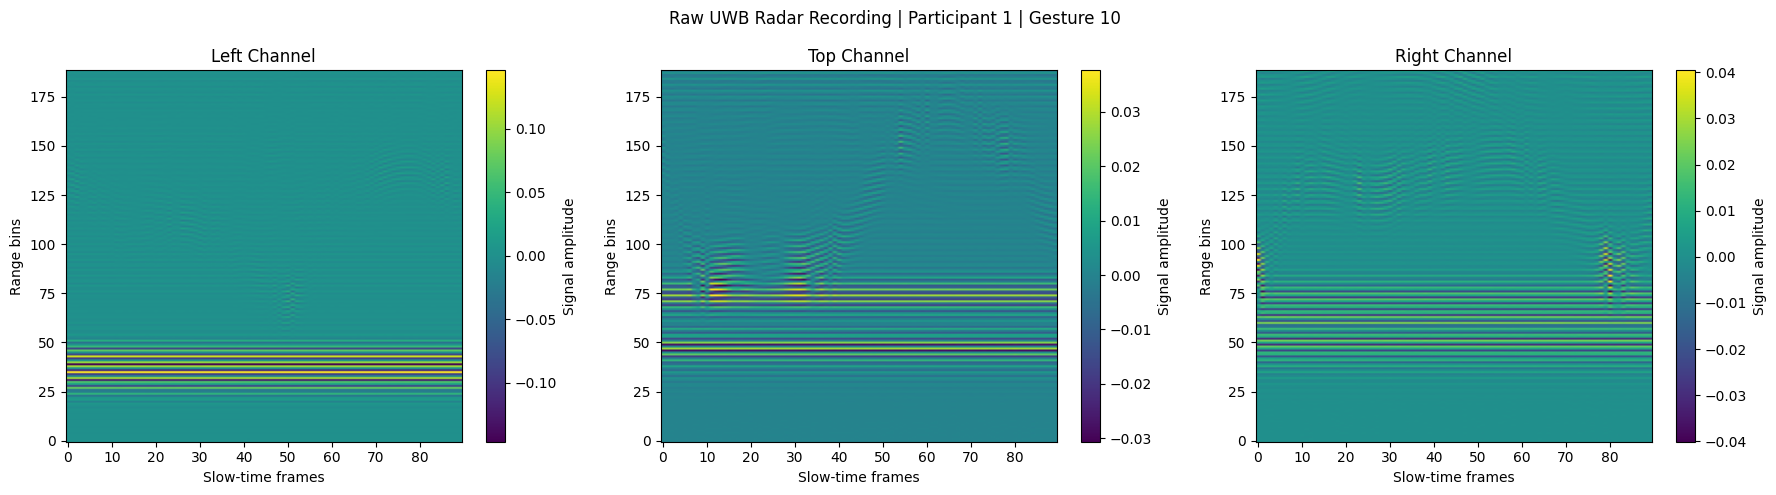

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load extracted dataset
X = np.load(
    "/content/uwb_processed/X_recordings.npy",
    mmap_mode="r"
)

y = np.load(
    "/content/uwb_processed/y_labels.npy"
)

metadata_df = pd.read_csv(
    "/content/uwb_processed/recording_metadata.csv"
)

# Select one recording
sample_index = 0
sample = X[sample_index]

participant = metadata_df.iloc[sample_index]["participant_id"]
gesture = metadata_df.iloc[sample_index]["gesture_id"]

print("Sample index:", sample_index)
print("Participant:", participant)
print("Gesture:", gesture)
print("Sample shape:", sample.shape)

# Plot all three radar channels
channel_names = ["Left", "Top", "Right"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, ax in enumerate(axes):

    im = ax.imshow(
        sample[:, :, i].T,
        aspect="auto",
        origin="lower",
        cmap="viridis"
    )

    ax.set_title(f"{channel_names[i]} Channel")
    ax.set_xlabel("Slow-time frames")
    ax.set_ylabel("Range bins")

    plt.colorbar(im, ax=ax, label="Signal amplitude")

plt.suptitle(
    f"Raw UWB Radar Recording | Participant {participant} | Gesture {gesture}"
)

plt.tight_layout()
plt.show()

In [ ]:
print("DATASET SIGNAL STATISTICS")
print("-------------------------")

print("Minimum:", np.min(X))
print("Maximum:", np.max(X))
print("Mean:", np.mean(X))
print("Standard deviation:", np.std(X))

print("\nCHANNEL-WISE STATISTICS")

for i, channel in enumerate(["Left", "Top", "Right"]):

    channel_data = X[:, :, :, i]

    print(f"\n{channel} Channel")
    print("Mean:", np.mean(channel_data))
    print("Std:", np.std(channel_data))
    print("Min:", np.min(channel_data))
    print("Max:", np.max(channel_data))

DATASET SIGNAL STATISTICS
-------------------------
Minimum: -0.49521762
Maximum: 0.48515785
Mean: 1.4384302e-07
Standard deviation: 0.019471686

CHANNEL-WISE STATISTICS

Left Channel
Mean: -1.8053232e-06
Std: 0.03079394
Min: -0.1602089
Max: 0.15803944

Top Channel
Mean: 2.0276934e-06
Std: 0.008840415
Min: -0.49521762
Max: 0.48515785

Right Channel
Mean: 2.0915901e-07
Std: 0.010536602
Min: -0.38441703
Max: 0.36450893


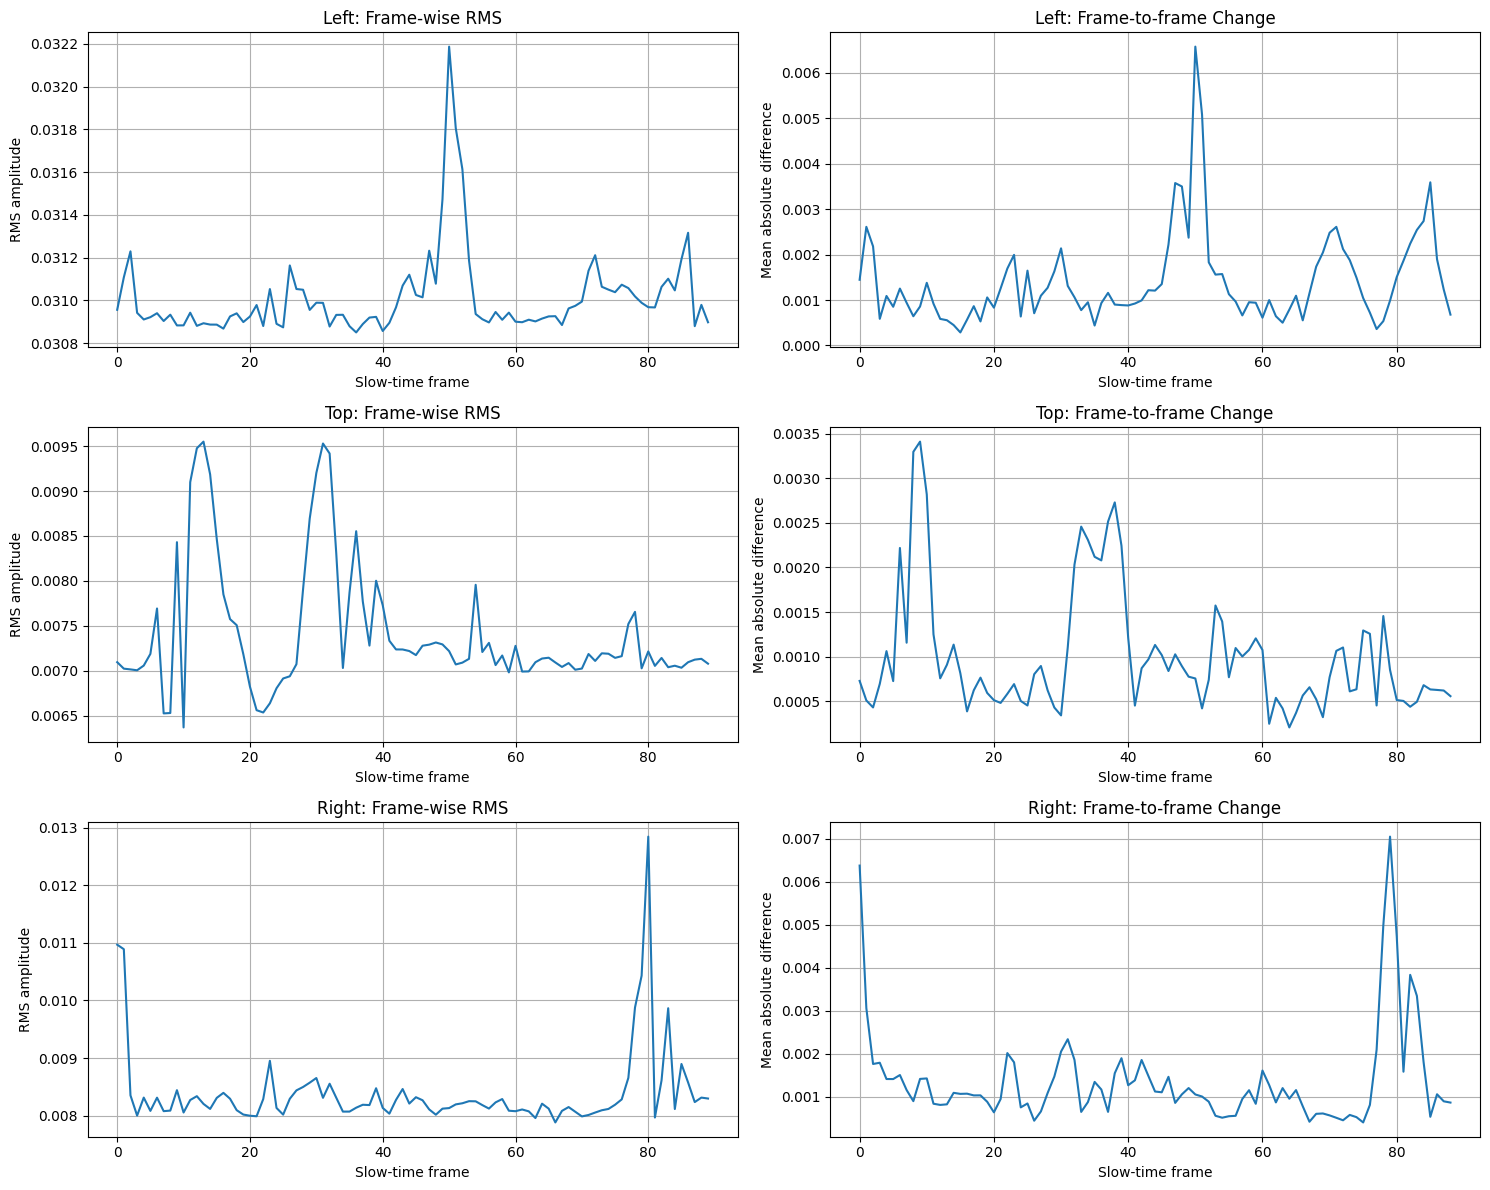

TEMPORAL ACTIVITY SUMMARY
-------------------------

Left Channel
Temporal variation: 0.0021141698
Mean frame difference: 0.0014056981

Top Channel
Temporal variation: 0.0017477246
Mean frame difference: 0.0009995288

Right Channel
Temporal variation: 0.002074072
Mean frame difference: 0.0013797411


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Select one recording
sample_index = 0
sample = X[sample_index]

channel_names = ["Left", "Top", "Right"]

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for i, channel in enumerate(channel_names):

    signal = sample[:, :, i]

    # Average signal energy at each time frame
    frame_rms = np.sqrt(np.mean(signal**2, axis=1))

    # Average change between consecutive frames
    frame_difference = np.mean(
        np.abs(np.diff(signal, axis=0)),
        axis=1
    )

    # Variation across time for each range bin
    range_variation = np.std(signal, axis=0)

    # Temporal energy
    axes[i, 0].plot(frame_rms)
    axes[i, 0].set_title(f"{channel}: Frame-wise RMS")
    axes[i, 0].set_xlabel("Slow-time frame")
    axes[i, 0].set_ylabel("RMS amplitude")
    axes[i, 0].grid(True)

    # Frame-to-frame change
    axes[i, 1].plot(frame_difference)
    axes[i, 1].set_title(f"{channel}: Frame-to-frame Change")
    axes[i, 1].set_xlabel("Slow-time frame")
    axes[i, 1].set_ylabel("Mean absolute difference")
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()

print("TEMPORAL ACTIVITY SUMMARY")
print("-------------------------")

for i, channel in enumerate(channel_names):

    signal = sample[:, :, i]

    print(f"\n{channel} Channel")
    print("Temporal variation:", np.mean(np.std(signal, axis=0)))
    print("Mean frame difference:",
          np.mean(np.abs(np.diff(signal, axis=0))))

GESTURE CLASS DISTRIBUTION
--------------------------
gesture_id
1     800
2     800
3     800
4     793
5     800
6     800
7     800
8     800
9     800
10    800
11    800
12    800
Name: count, dtype: int64


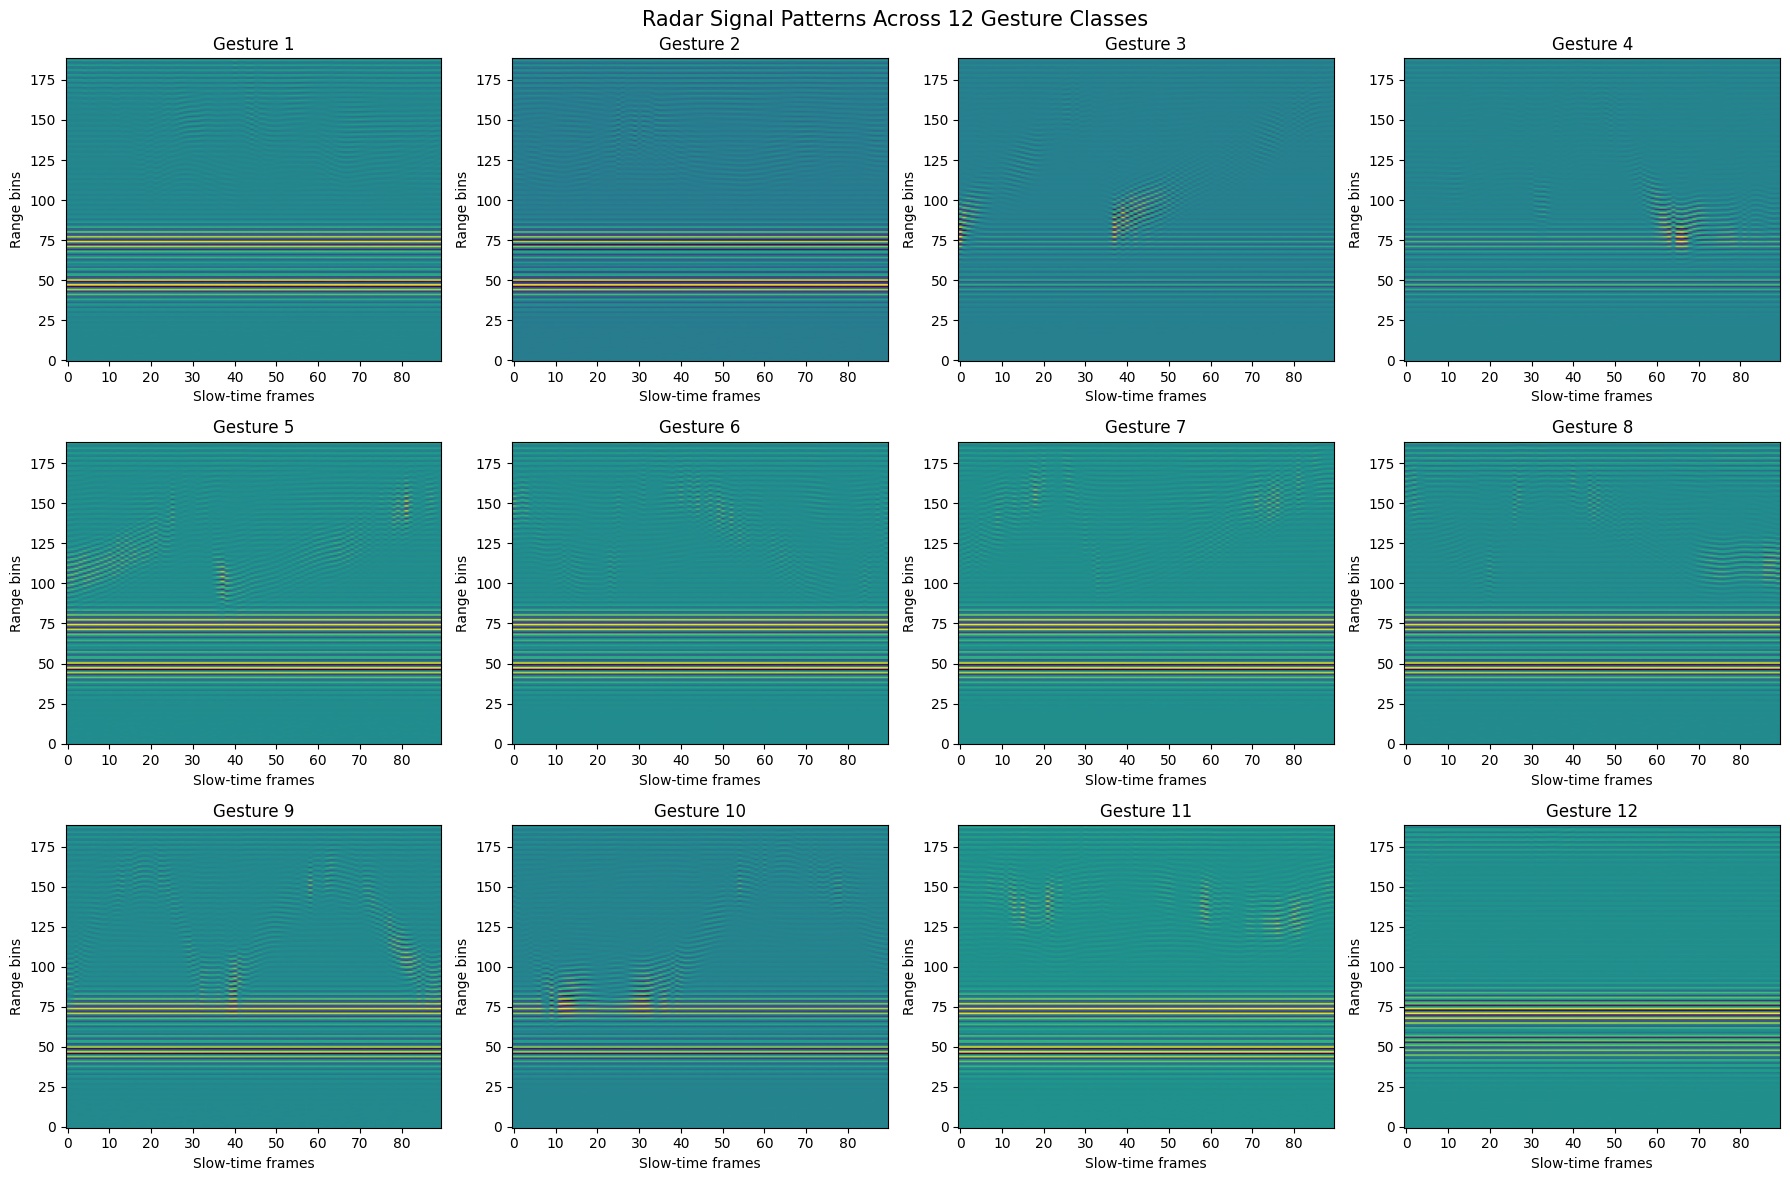

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load metadata
metadata_df = pd.read_csv(
    "/content/uwb_processed/recording_metadata.csv"
)

gesture_ids = sorted(metadata_df["gesture_id"].unique())

# Display class distribution
print("GESTURE CLASS DISTRIBUTION")
print("--------------------------")

print(
    metadata_df["gesture_id"]
    .value_counts()
    .sort_index()
)

# Select first recording of each gesture
fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for ax, gesture_id in zip(axes.flat, gesture_ids):

    # Find first recording belonging to this gesture
    sample_index = metadata_df.index[
        metadata_df["gesture_id"] == gesture_id
    ][0]

    # Select Top channel
    signal = X[sample_index, :, :, 1]

    ax.imshow(
        signal.T,
        aspect="auto",
        origin="lower",
        cmap="viridis"
    )

    ax.set_title(f"Gesture {gesture_id}")
    ax.set_xlabel("Slow-time frames")
    ax.set_ylabel("Range bins")

plt.suptitle(
    "Radar Signal Patterns Across 12 Gesture Classes",
    fontsize=15
)

plt.tight_layout()
plt.show()

PARTICIPANT × GESTURE DISTRIBUTION


gesture_id,1,2,3,4,5,6,7,8,9,10,11,12
participant_id,,,,,,,,,,,,
1,100,100,100,100,100,100,100,100,100,100,100,100
2,100,100,100,100,100,100,100,100,100,100,100,100
3,100,100,100,100,100,100,100,100,100,100,100,100
4,100,100,100,100,100,100,100,100,100,100,100,100
5,100,100,100,100,100,100,100,100,100,100,100,100
6,100,100,100,93,100,100,100,100,100,100,100,100
7,100,100,100,100,100,100,100,100,100,100,100,100
8,100,100,100,100,100,100,100,100,100,100,100,100



RECORDINGS PER PARTICIPANT
participant_id
1    1200
2    1200
3    1200
4    1200
5    1200
6    1193
7    1200
8    1200
Name: count, dtype: int64

RECORDINGS PER GESTURE
gesture_id
1     800
2     800
3     800
4     793
5     800
6     800
7     800
8     800
9     800
10    800
11    800
12    800
Name: count, dtype: int64


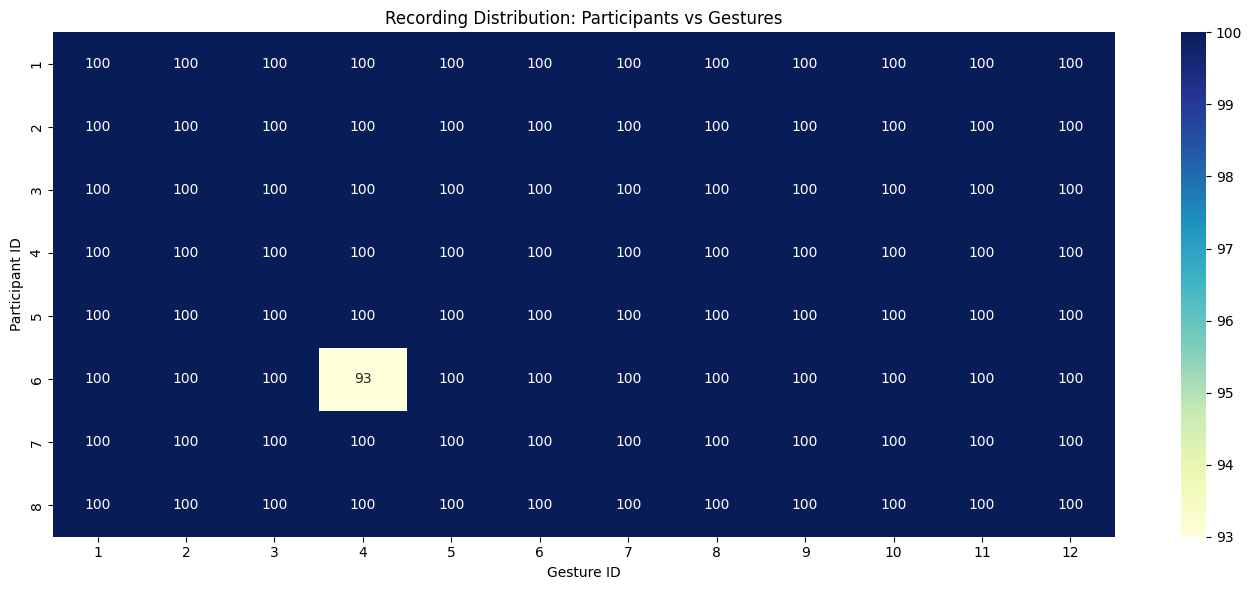

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

metadata_df = pd.read_csv(
    "/content/uwb_processed/recording_metadata.csv"
)

# Count recordings for each participant and gesture
distribution = pd.crosstab(
    metadata_df["participant_id"],
    metadata_df["gesture_id"]
)

print("PARTICIPANT × GESTURE DISTRIBUTION")
display(distribution)

print("\nRECORDINGS PER PARTICIPANT")
print(metadata_df["participant_id"].value_counts().sort_index())

print("\nRECORDINGS PER GESTURE")
print(metadata_df["gesture_id"].value_counts().sort_index())

# Visualize distribution
plt.figure(figsize=(14, 6))

sns.heatmap(
    distribution,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Recording Distribution: Participants vs Gestures")
plt.xlabel("Gesture ID")
plt.ylabel("Participant ID")
plt.tight_layout()
plt.show()

In [ ]:
class_counts = metadata_df["label"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Label": class_counts.index,
    "Gesture ID": class_counts.index + 1,
    "Recordings": class_counts.values,
    "Percentage": (
        class_counts.values / len(metadata_df) * 100
    ).round(2)
})

display(class_distribution)

print("Minimum class recordings:", class_counts.min())
print("Maximum class recordings:", class_counts.max())
print("Class count difference:", class_counts.max() - class_counts.min())

,Label,Gesture ID,Recordings,Percentage
0,0,1,800,8.34
1,1,2,800,8.34
2,2,3,800,8.34
3,3,4,793,8.27
4,4,5,800,8.34
5,5,6,800,8.34
6,6,7,800,8.34
7,7,8,800,8.34
8,8,9,800,8.34
9,9,10,800,8.34


Minimum class recordings: 793
Maximum class recordings: 800
Class count difference: 7


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Load metadata
metadata_df = pd.read_csv(
    "/content/uwb_processed/recording_metadata.csv"
)

groups = metadata_df["participant_id"].to_numpy()
indices = np.arange(len(metadata_df))

# First split: 75% train, 25% temporary holdout
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, holdout_idx = next(
    split1.split(indices, groups=groups)
)

# Second split: divide holdout into validation and test
holdout_groups = groups[holdout_idx]

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_relative, test_relative = next(
    split2.split(holdout_idx, groups=holdout_groups)
)

val_idx = holdout_idx[val_relative]
test_idx = holdout_idx[test_relative]

# Extract labels
y = metadata_df["label"].to_numpy()

# Verify participant separation
train_subjects = set(groups[train_idx])
val_subjects = set(groups[val_idx])
test_subjects = set(groups[test_idx])

assert train_subjects.isdisjoint(val_subjects)
assert train_subjects.isdisjoint(test_subjects)
assert val_subjects.isdisjoint(test_subjects)

# Save indices
np.savez(
    "/content/uwb_processed/data_splits.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("SUBJECT-INDEPENDENT SPLIT")
print("-------------------------")

print("Training participants:", sorted(train_subjects))
print("Validation participants:", sorted(val_subjects))
print("Testing participants:", sorted(test_subjects))

print("\nRECORDING COUNTS")
print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

print("\nCLASS DISTRIBUTION")

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    print(f"\n{name}:")
    print(pd.Series(y[idx]).value_counts().sort_index())

print("\nSUBJECT LEAKAGE CHECK: PASSED")

SUBJECT-INDEPENDENT SPLIT
-------------------------
Training participants: [np.int64(1), np.int64(3), np.int64(4), np.int64(5), np.int64(7), np.int64(8)]
Validation participants: [np.int64(2)]
Testing participants: [np.int64(6)]

RECORDING COUNTS
Training: 7200
Validation: 1200
Testing: 1193

CLASS DISTRIBUTION

Train:
0     600
1     600
2     600
3     600
4     600
5     600
6     600
7     600
8     600
9     600
10    600
11    600
Name: count, dtype: int64

Validation:
0     100
1     100
2     100
3     100
4     100
5     100
6     100
7     100
8     100
9     100
10    100
11    100
Name: count, dtype: int64

Test:
0     100
1     100
2     100
3      93
4     100
5     100
6     100
7     100
8     100
9     100
10    100
11    100
Name: count, dtype: int64

SUBJECT LEAKAGE CHECK: PASSED


In [ ]:
import numpy as np

# Load saved split indices
splits = np.load(
    "/content/uwb_processed/data_splits.npz"
)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]
test_idx = splits["test_idx"]

X = np.load(
    "/content/uwb_processed/X_recordings.npy",
    mmap_mode="r"
)

channel_names = ["Left", "Top", "Right"]

# Calculate statistics using training data only
channel_means = []
channel_stds = []

print("TRAINING-ONLY NORMALIZATION PARAMETERS")
print("---------------------------------------")

for i, channel in enumerate(channel_names):

    train_channel = X[train_idx, :, :, i]

    mean = float(np.mean(train_channel))
    std = float(np.std(train_channel))

    channel_means.append(mean)
    channel_stds.append(std)

    print(f"\n{channel} Channel")
    print("Training mean:", mean)
    print("Training std:", std)

    if std == 0:
        raise ValueError(f"Zero standard deviation: {channel}")

channel_means = np.array(channel_means, dtype=np.float32)
channel_stds = np.array(channel_stds, dtype=np.float32)

np.savez(
    "/content/uwb_processed/normalization_parameters.npz",
    means=channel_means,
    stds=channel_stds
)

print("\nNORMALIZATION PARAMETERS SAVED")

TRAINING-ONLY NORMALIZATION PARAMETERS
---------------------------------------

Left Channel
Training mean: -1.588560394338856e-06
Training std: 0.030848152935504913

Top Channel
Training mean: 2.1660368929588003e-06
Training std: 0.008617722429335117

Right Channel
Training mean: 4.263695529971301e-07
Training std: 0.010355623438954353

NORMALIZATION PARAMETERS SAVED


In [ ]:
from pathlib import Path
import numpy as np

OUTPUT_DIR = Path("/content/uwb_processed")

X_normalized = np.lib.format.open_memmap(
    OUTPUT_DIR / "X_normalized.npy",
    mode="w+",
    dtype=np.float32,
    shape=X.shape
)

for start in range(0, len(X), 128):

    end = min(start + 128, len(X))

    batch = np.asarray(X[start:end], dtype=np.float32)

    batch = (
        batch - channel_means.reshape(1, 1, 1, 3)
    ) / channel_stds.reshape(1, 1, 1, 3)

    X_normalized[start:end] = batch

X_normalized.flush()

print("NORMALIZATION COMPLETE")
print("Normalized shape:", X_normalized.shape)
print("Normalized dtype:", X_normalized.dtype)

NORMALIZATION COMPLETE
Normalized shape: (9593, 90, 189, 3)
Normalized dtype: float32


In [ ]:
print("NORMALIZATION VERIFICATION")
print("--------------------------")

for i, channel in enumerate(["Left", "Top", "Right"]):

    train_channel = X_normalized[train_idx, :, :, i]

    print(f"\n{channel} Channel")
    print("Mean:", float(np.mean(train_channel)))
    print("Std:", float(np.std(train_channel)))

print("\nAll values finite:",
      np.isfinite(X_normalized).all())

NORMALIZATION VERIFICATION
--------------------------

Left Channel
Mean: -1.6899390775648726e-09
Std: 1.0

Top Channel
Mean: -6.199599500433806e-09
Std: 1.0

Right Channel
Mean: 1.196064219888271e-10
Std: 0.9999998807907104

All values finite: True


In [ ]:
import numpy as np
from pathlib import Path

OUTPUT_DIR = Path("/content/uwb_processed")

X_normalized = np.load(
    OUTPUT_DIR / "X_normalized.npy",
    mmap_mode="r"
)

N = len(X_normalized)
features = np.lib.format.open_memmap(
    OUTPUT_DIR / "baseline_features.npy",
    mode="w+",
    dtype=np.float32,
    shape=(N, 729)
)

for start in range(0, N, 128):

    end = min(start + 128, N)

    batch = np.asarray(
        X_normalized[start:end],
        dtype=np.float32
    )

    # B x 9 temporal segments x 10 frames
    # x 9 range regions x 21 bins x 3 channels
    blocks = batch.reshape(
        -1, 9, 10, 9, 21, 3
    )

    mean_features = blocks.mean(axis=(2, 4))
    std_features = blocks.std(axis=(2, 4))
    abs_features = np.abs(blocks).mean(axis=(2, 4))

    combined = np.concatenate(
        [
            mean_features.reshape(len(batch), -1),
            std_features.reshape(len(batch), -1),
            abs_features.reshape(len(batch), -1)
        ],
        axis=1
    )

    features[start:end] = combined

    if (start // 128) % 10 == 0:
        print(f"Processed {end}/{N} recordings")

features.flush()

print("\nFEATURE EXTRACTION COMPLETE")
print("Feature shape:", features.shape)
print("Feature dtype:", features.dtype)
print("All finite:", np.isfinite(features).all())

Processed 128/9593 recordings
Processed 1408/9593 recordings
Processed 2688/9593 recordings
Processed 3968/9593 recordings
Processed 5248/9593 recordings
Processed 6528/9593 recordings
Processed 7808/9593 recordings
Processed 9088/9593 recordings

FEATURE EXTRACTION COMPLETE
Feature shape: (9593, 729)
Feature dtype: float32
All finite: True


In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Load features and labels
features = np.load(
    "/content/uwb_processed/baseline_features.npy",
    mmap_mode="r"
)

y = np.load(
    "/content/uwb_processed/y_labels.npy"
)

splits = np.load(
    "/content/uwb_processed/data_splits.npz"
)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]

X_train = np.asarray(features[train_idx])
X_val = np.asarray(features[val_idx])

y_train = y[train_idx]
y_val = y[val_idx]

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1500,
            C=1.0,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_features="sqrt",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():

    print(f"\nTraining: {name}")

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro"
    )

    results.append({
        "Model": name,
        "Validation Accuracy": accuracy,
        "Validation Macro F1": macro_f1
    })

    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_val,
        predictions,
        zero_division=0
    ))

results_df = pd.DataFrame(results)

print("\nBASELINE COMPARISON")
display(results_df)


Training: Logistic Regression
Accuracy: 0.7867
Macro F1: 0.7507

Classification Report:
              precision    recall  f1-score   support

           0       0.88      1.00      0.94       100
           1       1.00      0.99      0.99       100
           2       0.84      1.00      0.91       100
           3       0.88      0.94      0.91       100
           4       1.00      0.38      0.55       100
           5       0.86      0.81      0.84       100
           6       0.96      0.64      0.77       100
           7       0.80      1.00      0.89       100
           8       0.72      0.79      0.75       100
           9       0.75      0.89      0.81       100
          10       0.48      1.00      0.65       100
          11       0.00      0.00      0.00       100

    accuracy                           0.79      1200
   macro avg       0.76      0.79      0.75      1200
weighted avg       0.76      0.79      0.75      1200


Training: Random Forest
Accuracy: 0.6942
Ma

,Model,Validation Accuracy,Validation Macro F1
0,Logistic Regression,0.786667,0.750745
1,Random Forest,0.694167,0.639645


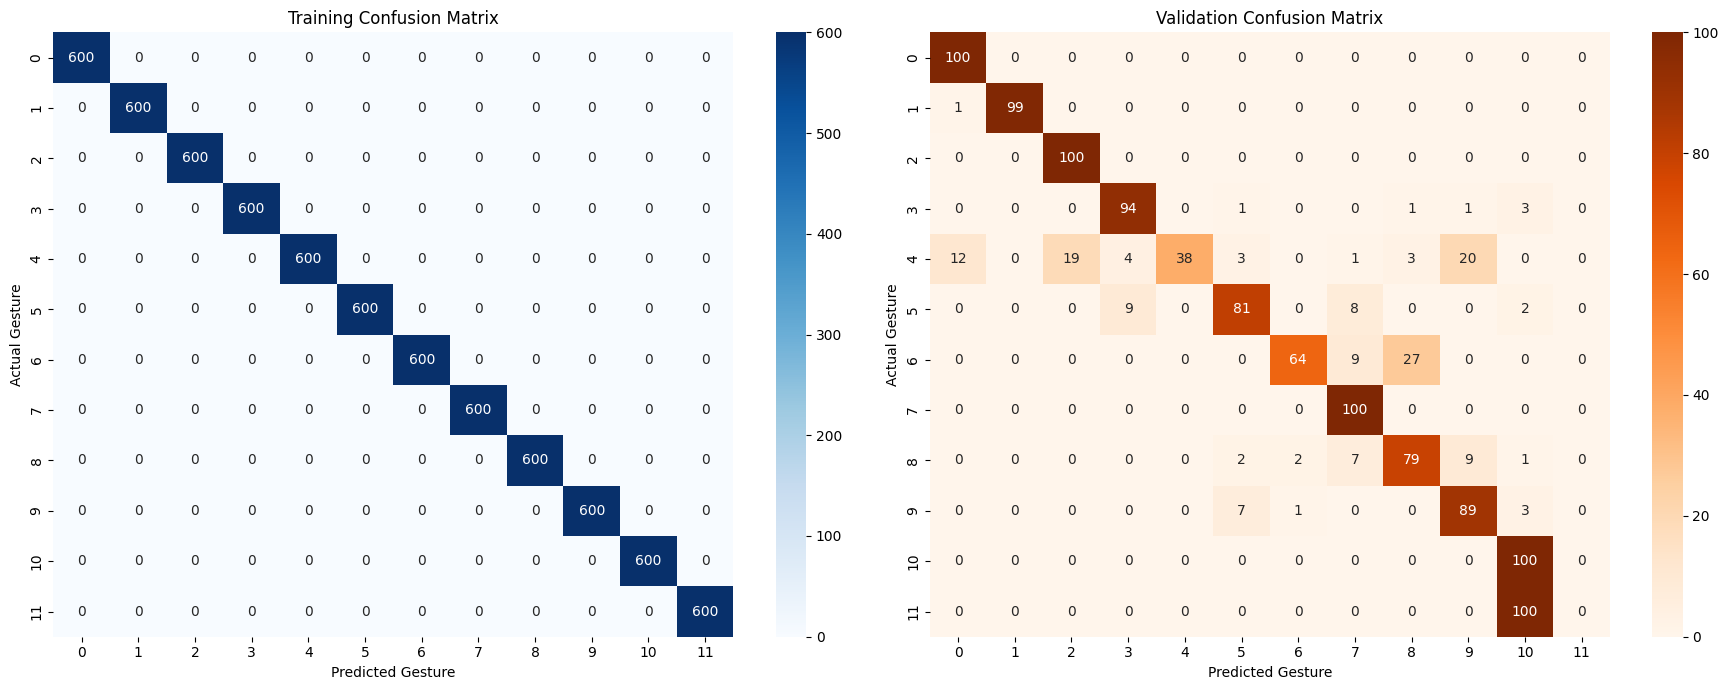

TRAIN ACCURACY: 1.0
VALIDATION ACCURACY: 0.7866666666666666

PREDICTIONS PER GESTURE
Gesture 1: 113 predictions
Gesture 2: 99 predictions
Gesture 3: 119 predictions
Gesture 4: 107 predictions
Gesture 5: 38 predictions
Gesture 6: 94 predictions
Gesture 7: 67 predictions
Gesture 8: 125 predictions
Gesture 9: 110 predictions
Gesture 10: 119 predictions
Gesture 11: 209 predictions
Gesture 12: 0 predictions


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score

# Load data
features = np.load(
    "/content/uwb_processed/baseline_features.npy",
    mmap_mode="r"
)

y = np.load("/content/uwb_processed/y_labels.npy")

splits = np.load("/content/uwb_processed/data_splits.npz")

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]

X_train = np.asarray(features[train_idx])
X_val = np.asarray(features[val_idx])

y_train = y[train_idx]
y_val = y[val_idx]

# Train Logistic Regression again
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1500,
        C=1.0,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

train_predictions = lr_model.predict(X_train)
val_predictions = lr_model.predict(X_val)

# Confusion matrices
labels = np.arange(12)

cm_train = confusion_matrix(
    y_train, train_predictions, labels=labels
)

cm_val = confusion_matrix(
    y_val, val_predictions, labels=labels
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    cm_train,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Training Confusion Matrix")
axes[0].set_xlabel("Predicted Gesture")
axes[0].set_ylabel("Actual Gesture")

sns.heatmap(
    cm_val,
    annot=True,
    fmt="d",
    cmap="Oranges",
    ax=axes[1]
)

axes[1].set_title("Validation Confusion Matrix")
axes[1].set_xlabel("Predicted Gesture")
axes[1].set_ylabel("Actual Gesture")

plt.tight_layout()
plt.show()

print("TRAIN ACCURACY:", accuracy_score(y_train, train_predictions))
print("VALIDATION ACCURACY:", accuracy_score(y_val, val_predictions))

print("\nPREDICTIONS PER GESTURE")
for gesture in labels:
    print(
        f"Gesture {gesture + 1}:",
        np.sum(val_predictions == gesture),
        "predictions"
    )

In [ ]:
import pandas as pd

confusion_df = pd.DataFrame(
    cm_val,
    index=[f"Actual G{i}" for i in range(1, 13)],
    columns=[f"Predicted G{i}" for i in range(1, 13)]
)

for i in range(12):
    confusion_df.iloc[i, i] = 0

confusion_pairs = (
    confusion_df.stack()
    .sort_values(ascending=False)
)

print("TOP 15 MISCLASSIFICATIONS")
display(confusion_pairs.head(15))

TOP 15 MISCLASSIFICATIONS


Actual G12  Predicted G11    100
Actual G7   Predicted G9      27
Actual G5   Predicted G10     20
            Predicted G3      19
            Predicted G1      12
Actual G6   Predicted G4       9
Actual G9   Predicted G10      9
Actual G7   Predicted G8       9
Actual G6   Predicted G8       8
Actual G9   Predicted G8       7
Actual G10  Predicted G6       7
Actual G5   Predicted G4       4
Actual G4   Predicted G11      3
Actual G10  Predicted G11      3
Actual G5   Predicted G6       3
dtype: int64

In [ ]:
import numpy as np
import pandas as pd

# Load metadata and features
metadata_df = pd.read_csv(
    "/content/uwb_processed/recording_metadata.csv"
)

features = np.load(
    "/content/uwb_processed/baseline_features.npy",
    mmap_mode="r"
)

splits = np.load(
    "/content/uwb_processed/data_splits.npz"
)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]

# Inspect gesture labels and recording counts
print("GESTURE LABEL VERIFICATION")
print("--------------------------")

print(
    metadata_df.groupby(
        ["gesture_id", "label"]
    ).size()
)

# Compare G11 and G12 in training and validation
for subset_name, indices in [
    ("TRAINING", train_idx),
    ("VALIDATION", val_idx)
]:

    print(f"\n{subset_name}")
    print("-" * 40)

    subset_metadata = metadata_df.iloc[indices]

    for gesture in [11, 12]:

        local_indices = indices[
            subset_metadata["gesture_id"].to_numpy() == gesture
        ]

        class_features = np.asarray(
            features[local_indices]
        )

        print(f"\nGesture {gesture}")
        print("Recordings:", len(local_indices))
        print("Feature mean:", np.mean(class_features))
        print("Feature std:", np.std(class_features))
        print("Mean absolute feature value:",
              np.mean(np.abs(class_features)))

# Compare training class centroids
g11_idx = train_idx[
    metadata_df.iloc[train_idx]["gesture_id"].to_numpy() == 11
]

g12_idx = train_idx[
    metadata_df.iloc[train_idx]["gesture_id"].to_numpy() == 12
]

centroid_11 = np.asarray(features[g11_idx]).mean(axis=0)
centroid_12 = np.asarray(features[g12_idx]).mean(axis=0)

centroid_distance = np.linalg.norm(
    centroid_11 - centroid_12
)

print("\nTRAINING CENTROID COMPARISON")
print("----------------------------")
print("Euclidean distance:", centroid_distance)
print("Centroid correlation:",
      np.corrcoef(centroid_11, centroid_12)[0, 1])

GESTURE LABEL VERIFICATION
--------------------------
gesture_id  label
1           0        800
2           1        800
3           2        800
4           3        793
5           4        800
6           5        800
7           6        800
8           7        800
9           8        800
10          9        800
11          10       800
12          11       800
dtype: int64

TRAINING
----------------------------------------

Gesture 11
Recordings: 600
Feature mean: 0.36682257
Feature std: 0.6066995
Mean absolute feature value: 0.37237734

Gesture 12
Recordings: 600
Feature mean: 0.3705352
Feature std: 0.7051761
Mean absolute feature value: 0.3775034

VALIDATION
----------------------------------------

Gesture 11
Recordings: 100
Feature mean: 0.3642623
Feature std: 0.5625447
Mean absolute feature value: 0.36909938

Gesture 12
Recordings: 100
Feature mean: 0.3642623
Feature std: 0.5625447
Mean absolute feature value: 0.36909938

TRAINING CENTROID COMPARISON
---------------------

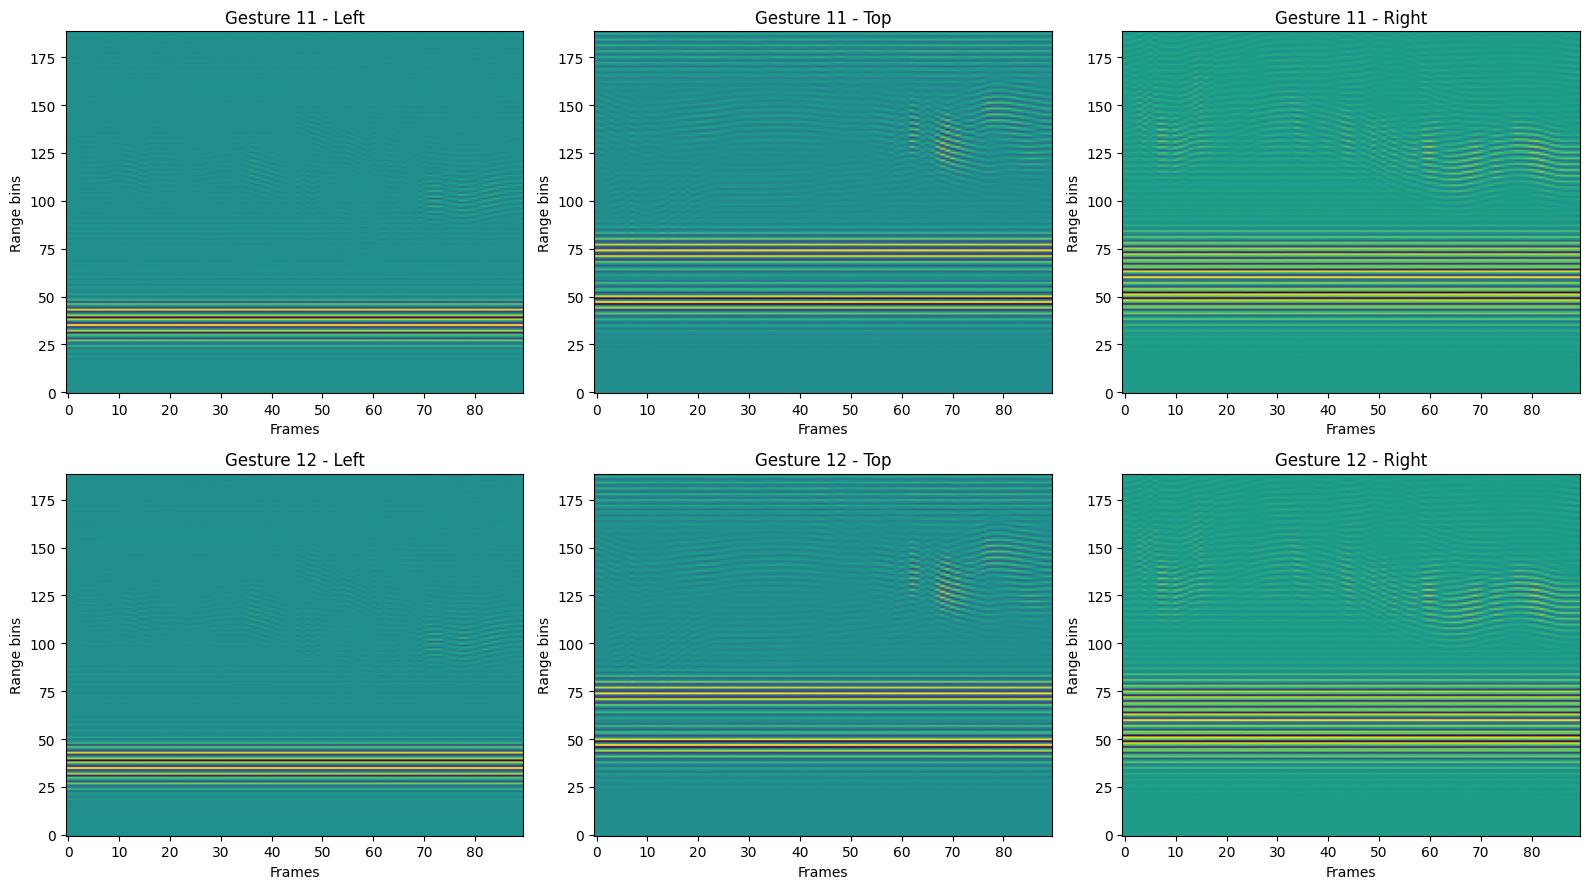

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for row, gesture in enumerate([11, 12]):

    sample_index = metadata_df.index[
        (metadata_df["participant_id"] == 2) &
        (metadata_df["gesture_id"] == gesture)
    ][0]

    sample = X[sample_index]

    for channel in range(3):

        axes[row, channel].imshow(
            sample[:, :, channel].T,
            aspect="auto",
            origin="lower",
            cmap="viridis"
        )

        axes[row, channel].set_title(
            f"Gesture {gesture} - "
            f"{['Left', 'Top', 'Right'][channel]}"
        )

        axes[row, channel].set_xlabel("Frames")
        axes[row, channel].set_ylabel("Range bins")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

metadata_df = pd.read_csv(
    "/content/uwb_processed/recording_metadata.csv"
)

features = np.load(
    "/content/uwb_processed/baseline_features.npy",
    mmap_mode="r"
)

splits = np.load(
    "/content/uwb_processed/data_splits.npz"
)

val_idx = splits["val_idx"]

# Reset metadata index to make positional indexing explicit
val_metadata = metadata_df.iloc[val_idx].reset_index(drop=True)

print("VALIDATION DATA VERIFICATION")
print("----------------------------")

class_features = {}

for gesture in [11, 12]:

    positions = np.flatnonzero(
        val_metadata["gesture_id"].to_numpy() == gesture
    )

    global_indices = val_idx[positions]

    current_features = np.asarray(features[global_indices])

    class_features[gesture] = current_features

    print(f"\nGesture {gesture}")
    print("Recording count:", len(global_indices))
    print("Source files:")
    print(val_metadata.iloc[positions]["source_file"].unique())

    print("Feature mean:", current_features.mean())
    print("Feature std:", current_features.std())
    print("Mean absolute value:", np.abs(current_features).mean())

# Compare actual feature matrices
g11 = class_features[11]
g12 = class_features[12]

print("\nDIRECT COMPARISON")
print("-----------------")

print("Matrices identical:", np.array_equal(g11, g12))

print(
    "Mean absolute difference:",
    np.mean(np.abs(g11 - g12))
)

print(
    "Maximum absolute difference:",
    np.max(np.abs(g11 - g12))
)

print(
    "Mean centroid distance:",
    np.linalg.norm(g11.mean(axis=0) - g12.mean(axis=0))
)

print(
    "Centroid correlation:",
    np.corrcoef(g11.mean(axis=0), g12.mean(axis=0))[0, 1]
)

VALIDATION DATA VERIFICATION
----------------------------

Gesture 11
Recording count: 100
Source files:
['HV_02_G11_RawData.mat']
Feature mean: 0.3642623
Feature std: 0.5625447
Mean absolute value: 0.36909938

Gesture 12
Recording count: 100
Source files:
['HV_02_G12_RawData.mat']
Feature mean: 0.3642623
Feature std: 0.5625447
Mean absolute value: 0.36909938

DIRECT COMPARISON
-----------------
Matrices identical: True
Mean absolute difference: 0.0
Maximum absolute difference: 0.0
Mean centroid distance: 0.0
Centroid correlation: 1.0


In [ ]:
from scipy.io import loadmat
from pathlib import Path
import numpy as np
import hashlib

# Locate original files
g11_path = list(DATA_DIR.rglob("HV_02_G11_RawData.mat"))[0]
g12_path = list(DATA_DIR.rglob("HV_02_G12_RawData.mat"))[0]

print("G11 FILE:", g11_path)
print("G12 FILE:", g12_path)

# Calculate file hashes
def file_hash(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

print("\nFILE HASH COMPARISON")
print("G11:", file_hash(g11_path))
print("G12:", file_hash(g12_path))

print("\nRAW CHANNEL COMPARISON")
mat11 = loadmat(g11_path)
mat12 = loadmat(g12_path)

for channel in ["Left", "Top", "Right"]:

    a = np.asarray(mat11[channel])
    b = np.asarray(mat12[channel])

    print(f"\n{channel} Channel")
    print("G11 shape:", a.shape)
    print("G12 shape:", b.shape)
    print("Exactly identical:", np.array_equal(a, b))
    print("Mean absolute difference:", np.mean(np.abs(a - b)))
    print("G11 mean:", np.mean(a))
    print("G12 mean:", np.mean(b))

# Compare extracted recordings directly
metadata_df = pd.read_csv(
    "/content/uwb_processed/recording_metadata.csv"
)

g11_index = metadata_df.index[
    (metadata_df["participant_id"] == 2) &
    (metadata_df["gesture_id"] == 11)
].to_numpy()

g12_index = metadata_df.index[
    (metadata_df["participant_id"] == 2) &
    (metadata_df["gesture_id"] == 12)
].to_numpy()

X = np.load(
    "/content/uwb_processed/X_recordings.npy",
    mmap_mode="r"
)

print("\nEXTRACTED RECORDING COMPARISON")
print(
    "First recording identical:",
    np.array_equal(X[g11_index[0]], X[g12_index[0]])
)

G11 FILE: /content/uwb_gestures/uwb-gestures/HV_02/HV_02_G11_RawData.mat
G12 FILE: /content/uwb_gestures/uwb-gestures/HV_02/HV_02_G12_RawData.mat

FILE HASH COMPARISON
G11: 54a4a9a0711b2ca3fb9029f28443bac206744a8485ae46250192538a000933d6
G12: dc904ad9d3653b48d6f49c4cdf0eb717d3bbf0e714799d4a52cff910f8dc4762

RAW CHANNEL COMPARISON

Left Channel
G11 shape: (9000, 189)
G12 shape: (9000, 189)
Exactly identical: True
Mean absolute difference: 0.0
G11 mean: -5.915712457059311e-07
G12 mean: -5.915712457059311e-07

Top Channel
G11 shape: (9000, 189)
G12 shape: (9000, 189)
Exactly identical: True
Mean absolute difference: 0.0
G11 mean: 2.6110627207647333e-06
G12 mean: 2.6110627207647333e-06

Right Channel
G11 shape: (9000, 189)
G12 shape: (9000, 189)
Exactly identical: True
Mean absolute difference: 0.0
G11 mean: -1.3399736006131517e-06
G12 mean: -1.3399736006131517e-06

EXTRACTED RECORDING COMPARISON
First recording identical: True


In [ ]:
import numpy as np
import pandas as pd
import hashlib
from scipy.io import loadmat

from collections import defaultdict

mat_files = sorted(DATA_DIR.rglob("*.mat"))

# Store signatures
full_signatures = defaultdict(list)
channel_signatures = {
    "Left": defaultdict(list),
    "Top": defaultdict(list),
    "Right": defaultdict(list)
}

def array_hash(array):
    array = np.ascontiguousarray(array)

    h = hashlib.sha256()
    h.update(str(array.shape).encode())
    h.update(str(array.dtype).encode())
    h.update(array.tobytes())

    return h.hexdigest()

print("SCANNING ALL 96 MAT FILES...")

for file_path in mat_files:

    import re

    match = re.search(
        r"HV_(\d+)_G(\d+)_RawData\.mat",
        file_path.name
    )

    participant = int(match.group(1))
    gesture = int(match.group(2))

    mat = loadmat(file_path)

    channel_hashes = {}

    for channel in ["Left", "Top", "Right"]:

        signature = array_hash(mat[channel])

        channel_hashes[channel] = signature

        channel_signatures[channel][signature].append(
            (participant, gesture)
        )

    combined_signature = "|".join(
        channel_hashes[c]
        for c in ["Left", "Top", "Right"]
    )

    full_signatures[combined_signature].append(
        (participant, gesture)
    )

# Report complete duplicate recordings
print("\nIDENTICAL THREE-CHANNEL DATASETS")
print("--------------------------------")

full_duplicates = []

for signature, entries in full_signatures.items():

    if len(entries) > 1:

        full_duplicates.append(entries)

        print("Duplicate entries:", entries)

# Report individual channel duplicates
print("\nINDIVIDUAL CHANNEL DUPLICATES")
print("-----------------------------")

for channel, signatures in channel_signatures.items():

    print(f"\n{channel} channel:")

    found = False

    for signature, entries in signatures.items():

        if len(entries) > 1:

            found = True
            print(entries)

    if not found:
        print("No duplicates detected.")

# Summary
print("\nAUDIT SUMMARY")
print("-------------")
print("Total MAT files scanned:", len(mat_files))
print("Duplicate full-channel groups:", len(full_duplicates))
print("Unique full-channel signatures:", len(full_signatures))

SCANNING ALL 96 MAT FILES...

IDENTICAL THREE-CHANNEL DATASETS
--------------------------------
Duplicate entries: [(2, 11), (2, 12)]

INDIVIDUAL CHANNEL DUPLICATES
-----------------------------

Left channel:
[(2, 11), (2, 12)]

Top channel:
[(2, 11), (2, 12)]

Right channel:
[(2, 11), (2, 12)]

AUDIT SUMMARY
-------------
Total MAT files scanned: 96
Duplicate full-channel groups: 1
Unique full-channel signatures: 95


In [ ]:
import numpy as np
import pandas as pd

# Load metadata
metadata_df = pd.read_csv(
    "/content/uwb_processed/recording_metadata.csv"
)

# Exclude duplicated recordings:
# Participant 2, Gestures 11 and 12
excluded_mask = (
    (metadata_df["participant_id"] == 2) &
    (metadata_df["gesture_id"].isin([11, 12]))
)

excluded_idx = np.flatnonzero(excluded_mask.to_numpy())
eligible_idx = np.flatnonzero(~excluded_mask.to_numpy())

# Define participant groups explicitly
train_subjects = [2, 3, 4, 5, 7, 8]
val_subjects = [1]
test_subjects = [6]

# Generate split indices
train_idx = eligible_idx[
    metadata_df.iloc[eligible_idx]["participant_id"]
    .isin(train_subjects).to_numpy()
]

val_idx = eligible_idx[
    metadata_df.iloc[eligible_idx]["participant_id"]
    .isin(val_subjects).to_numpy()
]

test_idx = eligible_idx[
    metadata_df.iloc[eligible_idx]["participant_id"]
    .isin(test_subjects).to_numpy()
]

# Verify no overlap
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

# Verify excluded files
assert len(excluded_idx) == 200

# Save cleaned split
np.savez(
    "/content/uwb_processed/clean_data_splits.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    excluded_idx=excluded_idx
)

print("CLEAN EXPERIMENTAL DATASET")
print("--------------------------")

print("Excluded recordings:", len(excluded_idx))
print("Eligible recordings:", len(eligible_idx))

print("\nTRAINING")
print("Participants:", train_subjects)
print("Recordings:", len(train_idx))

print("\nVALIDATION")
print("Participants:", val_subjects)
print("Recordings:", len(val_idx))

print("\nTESTING")
print("Participants:", test_subjects)
print("Recordings:", len(test_idx))

print("\nCLASS DISTRIBUTION")

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    print(f"\n{name}:")
    print(
        metadata_df.iloc[idx]["gesture_id"]
        .value_counts()
        .sort_index()
    )

print("\nCLEAN SPLIT VALIDATION: PASSED")

CLEAN EXPERIMENTAL DATASET
--------------------------
Excluded recordings: 200
Eligible recordings: 9393

TRAINING
Participants: [2, 3, 4, 5, 7, 8]
Recordings: 7000

VALIDATION
Participants: [1]
Recordings: 1200

TESTING
Participants: [6]
Recordings: 1193

CLASS DISTRIBUTION

Train:
gesture_id
1     600
2     600
3     600
4     600
5     600
6     600
7     600
8     600
9     600
10    600
11    500
12    500
Name: count, dtype: int64

Validation:
gesture_id
1     100
2     100
3     100
4     100
5     100
6     100
7     100
8     100
9     100
10    100
11    100
12    100
Name: count, dtype: int64

Test:
gesture_id
1     100
2     100
3     100
4      93
5     100
6     100
7     100
8     100
9     100
10    100
11    100
12    100
Name: count, dtype: int64

CLEAN SPLIT VALIDATION: PASSED


In [ ]:
import numpy as np
from pathlib import Path

OUTPUT_DIR = Path("/content/uwb_processed")

X = np.load(
    OUTPUT_DIR / "X_recordings.npy",
    mmap_mode="r"
)

clean_splits = np.load(
    OUTPUT_DIR / "clean_data_splits.npz"
)

train_idx = clean_splits["train_idx"]
val_idx = clean_splits["val_idx"]
test_idx = clean_splits["test_idx"]
excluded_idx = clean_splits["excluded_idx"]

channel_names = ["Left", "Top", "Right"]

channel_means = []
channel_stds = []

for i, channel in enumerate(channel_names):

    train_channel = X[train_idx, :, :, i]

    mean = float(np.mean(train_channel))
    std = float(np.std(train_channel))

    channel_means.append(mean)
    channel_stds.append(std)

    print(f"{channel}: mean={mean:.8f}, std={std:.8f}")

channel_means = np.array(channel_means, dtype=np.float32)
channel_stds = np.array(channel_stds, dtype=np.float32)

np.savez(
    OUTPUT_DIR / "clean_normalization_parameters.npz",
    means=channel_means,
    stds=channel_stds
)

print("\nCLEAN NORMALIZATION PARAMETERS SAVED")

Left: mean=-0.00000158, std=0.03086228
Top: mean=0.00000273, std=0.00862637
Right: mean=0.00000008, std=0.01040288

CLEAN NORMALIZATION PARAMETERS SAVED


In [ ]:
X_clean = np.lib.format.open_memmap(
    OUTPUT_DIR / "X_clean_normalized.npy",
    mode="w+",
    dtype=np.float32,
    shape=X.shape
)

for start in range(0, len(X), 128):

    end = min(start + 128, len(X))

    batch = np.asarray(X[start:end], dtype=np.float32)

    batch = (
        batch - channel_means.reshape(1, 1, 1, 3)
    ) / channel_stds.reshape(1, 1, 1, 3)

    X_clean[start:end] = batch

X_clean.flush()

print("Clean normalized shape:", X_clean.shape)
print("All values finite:", np.isfinite(X_clean).all())

for i, channel in enumerate(channel_names):

    values = X_clean[train_idx, :, :, i]

    print(
        f"{channel}: mean={np.mean(values):.8f}, "
        f"std={np.std(values):.8f}"
    )

Clean normalized shape: (9593, 90, 189, 3)
All values finite: True
Left: mean=0.00000000, std=1.00000000
Top: mean=-0.00000000, std=1.00000000
Right: mean=0.00000001, std=0.99999994


In [ ]:
features_clean = np.lib.format.open_memmap(
    OUTPUT_DIR / "baseline_features_clean.npy",
    mode="w+",
    dtype=np.float32,
    shape=(len(X_clean), 729)
)

for start in range(0, len(X_clean), 128):

    end = min(start + 128, len(X_clean))

    batch = np.asarray(
        X_clean[start:end],
        dtype=np.float32
    )

    blocks = batch.reshape(-1, 9, 10, 9, 21, 3)

    mean_features = blocks.mean(axis=(2, 4))
    std_features = blocks.std(axis=(2, 4))
    abs_features = np.abs(blocks).mean(axis=(2, 4))

    combined = np.concatenate(
        [
            mean_features.reshape(len(batch), -1),
            std_features.reshape(len(batch), -1),
            abs_features.reshape(len(batch), -1)
        ],
        axis=1
    )

    features_clean[start:end] = combined

features_clean.flush()

print("CLEAN FEATURE EXTRACTION COMPLETE")
print("Shape:", features_clean.shape)
print("All finite:", np.isfinite(features_clean).all())

CLEAN FEATURE EXTRACTION COMPLETE
Shape: (9593, 729)
All finite: True


In [ ]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

metadata_df = pd.read_csv(
    OUTPUT_DIR / "recording_metadata.csv"
)

y = metadata_df["label"].to_numpy()

features_clean = np.load(
    OUTPUT_DIR / "baseline_features_clean.npy",
    mmap_mode="r"
)

X_train = np.asarray(features_clean[train_idx])
X_val = np.asarray(features_clean[val_idx])

y_train = y[train_idx]
y_val = y[val_idx]

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1500,
            C=1.0,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_features="sqrt",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro"
    )

    results.append({
        "Model": name,
        "Validation Accuracy": accuracy,
        "Validation Macro F1": macro_f1
    })

    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))

    print(classification_report(
        y_val,
        predictions,
        zero_division=0
    ))

results_df = pd.DataFrame(results)

print("\nCLEAN BASELINE COMPARISON")
display(results_df)

results_df.to_csv(
    OUTPUT_DIR / "clean_baseline_results.csv",
    index=False
)


Training Logistic Regression...
Accuracy: 0.845
Macro F1: 0.8469
              precision    recall  f1-score   support

           0       1.00      0.60      0.75       100
           1       0.76      0.93      0.83       100
           2       0.82      0.93      0.87       100
           3       0.95      0.94      0.94       100
           4       0.71      0.92      0.80       100
           5       0.92      0.95      0.94       100
           6       0.94      0.67      0.78       100
           7       0.96      0.70      0.81       100
           8       1.00      0.76      0.86       100
           9       0.56      0.90      0.69       100
          10       0.92      0.84      0.88       100
          11       1.00      1.00      1.00       100

    accuracy                           0.84      1200
   macro avg       0.88      0.85      0.85      1200
weighted avg       0.88      0.84      0.85      1200


Training Random Forest...
Accuracy: 0.7833
Macro F1: 0.739
       

,Model,Validation Accuracy,Validation Macro F1
0,Logistic Regression,0.845000,0.84693
1,Random Forest,0.783333,0.73896


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Training device: CPU")

PyTorch version: 2.11.0+cpu
CUDA available: False
Training device: CPU


In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, classification_report
from pathlib import Path

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

OUTPUT_DIR = Path("/content/uwb_processed")

# Load clean data
X = np.load(
    OUTPUT_DIR / "X_clean_normalized.npy",
    mmap_mode="r"
)

metadata = pd.read_csv(
    OUTPUT_DIR / "recording_metadata.csv"
)

splits = np.load(
    OUTPUT_DIR / "clean_data_splits.npz"
)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]

y = metadata["label"].to_numpy(dtype=np.int64)

# Dataset
class RadarDataset(Dataset):

    def __init__(self, indices):
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):

        idx = self.indices[position]

        sample = np.array(
            X[idx],
            dtype=np.float32,
            copy=True
        )

        # Convert (90, 189, 3) to (3, 90, 189)
        sample = np.transpose(sample, (2, 0, 1))

        return (
            torch.from_numpy(sample),
            torch.tensor(y[idx], dtype=torch.long)
        )

train_dataset = RadarDataset(train_idx)
val_dataset = RadarDataset(val_idx)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# CNN architecture
class RadarCNN(nn.Module):

    def __init__(self, num_classes=12):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = RadarCNN().to(DEVICE)

# Class weights for the slightly smaller G11 and G12 classes
class_counts = np.bincount(y[train_idx], minlength=12)

class_weights = (
    len(train_idx) /
    (12 * class_counts)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

# Training configuration
EPOCHS = 30
PATIENCE = 7

best_f1 = -1
epochs_without_improvement = 0

best_model_path = OUTPUT_DIR / "best_radar_cnn.pth"

print("CNN TRAINING STARTED")
print("Device:", DEVICE)
print("Training recordings:", len(train_dataset))
print("Validation recordings:", len(val_dataset))

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    train_predictions = []
    train_targets = []

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(DEVICE)
        batch_y = batch_y.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        train_predictions.extend(
            outputs.argmax(dim=1).detach().cpu().numpy()
        )

        train_targets.extend(
            batch_y.detach().cpu().numpy()
        )

    train_loss = running_loss / len(train_loader)

    train_acc = accuracy_score(
        train_targets,
        train_predictions
    )

    # Validation
    model.eval()

    val_predictions = []
    val_targets = []
    val_loss = 0.0

    with torch.no_grad():

        for batch_x, batch_y in val_loader:

            batch_x = batch_x.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            outputs = model(batch_x)

            loss = criterion(outputs, batch_y)
            val_loss += loss.item()

            val_predictions.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )

            val_targets.extend(
                batch_y.cpu().numpy()
            )

    val_loss /= len(val_loader)

    val_acc = accuracy_score(
        val_targets,
        val_predictions
    )

    val_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro"
    )

    scheduler.step(val_f1)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

    # Save best model
    if val_f1 > best_f1:

        best_f1 = val_f1
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            best_model_path
        )

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")
        break

print("\nCNN TRAINING COMPLETE")
print("Best validation Macro F1:", round(best_f1, 4))
print("Best model saved:", best_model_path)

CNN TRAINING STARTED
Device: cpu
Training recordings: 7000
Validation recordings: 1200
Epoch 01/30 | Train Loss: 1.8791 | Train Acc: 0.3043 | Val Loss: 1.5253 | Val Acc: 0.5667 | Val Macro F1: 0.4869
Epoch 02/30 | Train Loss: 1.2483 | Train Acc: 0.5179 | Val Loss: 1.3883 | Val Acc: 0.5217 | Val Macro F1: 0.4740
Epoch 03/30 | Train Loss: 0.8854 | Train Acc: 0.6611 | Val Loss: 0.7603 | Val Acc: 0.7258 | Val Macro F1: 0.6869
Epoch 04/30 | Train Loss: 0.7073 | Train Acc: 0.7280 | Val Loss: 1.0978 | Val Acc: 0.5267 | Val Macro F1: 0.5377
Epoch 05/30 | Train Loss: 0.5844 | Train Acc: 0.7839 | Val Loss: 0.5017 | Val Acc: 0.8417 | Val Macro F1: 0.8278
Epoch 06/30 | Train Loss: 0.5016 | Train Acc: 0.8217 | Val Loss: 0.5748 | Val Acc: 0.8133 | Val Macro F1: 0.7874
Epoch 07/30 | Train Loss: 0.4515 | Train Acc: 0.8344 | Val Loss: 0.3522 | Val Acc: 0.8583 | Val Macro F1: 0.8466
Epoch 08/30 | Train Loss: 0.3651 | Train Acc: 0.8704 | Val Loss: 0.3858 | Val Acc: 0.8733 | Val Macro F1: 0.8740
Epoch 09/

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

PROJECT = Path('/content/drive/MyDrive/RadarGestureEdgeAI')
for sub in ['raw', 'processed', 'models', 'results', 'figures']:
    (PROJECT / sub).mkdir(parents=True, exist_ok=True)

print("Project folders:", sorted(p.name for p in PROJECT.iterdir()))

Mounted at /content/drive
Project folders: ['figures', 'models', 'processed', 'raw', 'results']


In [2]:
import requests, zipfile, re, shutil
import numpy as np
import pandas as pd
from scipy.io import loadmat

URL = "https://ssd.mathworks.com/supportfiles/SPT/data/uwb-gestures.zip"
ZIP_DRIVE = PROJECT / 'raw' / 'uwb-gestures.zip'
ZIP_LOCAL = Path('/content/uwb-gestures.zip')
DATA_DIR  = Path('/content/uwb_gestures')
LOCAL     = Path('/content/uwb_processed')
LOCAL.mkdir(exist_ok=True)

CHANNELS, FRAMES, BINS = ['Left', 'Top', 'Right'], 90, 189

# 1. Download only if Drive doesn't have it yet
if not ZIP_DRIVE.exists():
    print("Downloading dataset (one time only)...")
    with requests.get(URL, stream=True, timeout=120,
                      headers={"User-Agent": "Mozilla/5.0"}) as r:
        r.raise_for_status()
        with open(ZIP_LOCAL, 'wb') as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    assert zipfile.is_zipfile(ZIP_LOCAL), "Download is not a valid ZIP"
    shutil.copy2(ZIP_LOCAL, ZIP_DRIVE)
    print("Saved ZIP to Drive.")
else:
    print("ZIP already in Drive, copying locally...")
    shutil.copy2(ZIP_DRIVE, ZIP_LOCAL)

# 2. Extract locally
with zipfile.ZipFile(ZIP_LOCAL) as zf:
    assert zf.testzip() is None, "Corrupted ZIP"
    zf.extractall(DATA_DIR)

mat_files = sorted(DATA_DIR.rglob('*.mat'))
assert len(mat_files) == 96, f"Expected 96 files, found {len(mat_files)}"
pattern = re.compile(r'HV_(\d+)_G(\d+)_RawData\.mat$', re.IGNORECASE)

# 3. Load each file once, write recordings into a disk-backed array
counts = []
for p in mat_files:
    counts.append(loadmat(p, variable_names=['Left'])['Left'].shape[0] // FRAMES)
total = sum(counts)
print("Total recordings:", total)

X = np.lib.format.open_memmap(LOCAL / 'X_recordings.npy', mode='w+',
                              dtype=np.float32,
                              shape=(total, FRAMES, BINS, len(CHANNELS)))
metadata, ptr = [], 0

for i, p in enumerate(mat_files):
    m = pattern.search(p.name)
    subject, gesture = int(m.group(1)), int(m.group(2))
    mat = loadmat(p)
    n = counts[i]
    stacked = np.stack(
        [np.asarray(mat[c], dtype=np.float32).reshape(n, FRAMES, BINS)
         for c in CHANNELS], axis=-1)
    X[ptr:ptr + n] = stacked
    for r in range(n):
        metadata.append({"participant_id": subject, "gesture_id": gesture,
                         "label": gesture - 1, "recording_number": r + 1,
                         "source_file": p.name})
    ptr += n
    if (i + 1) % 12 == 0:
        print(f"Processed {i + 1}/96 files")

X.flush()
meta = pd.DataFrame(metadata)

# Flag the duplicate files you discovered (kept in data, excluded at split time)
meta["is_duplicate"] = (meta.participant_id == 2) & meta.gesture_id.isin([11, 12])

meta.to_csv(LOCAL / 'recording_metadata.csv', index=False)
np.save(LOCAL / 'y_labels.npy', meta['label'].to_numpy(np.int64))

assert ptr == total == 9593
assert meta.is_duplicate.sum() == 200
print("Local build complete:", X.shape)

# 4. Copy results to Drive
for f in ['X_recordings.npy', 'recording_metadata.csv', 'y_labels.npy']:
    shutil.copy2(LOCAL / f, PROJECT / 'processed' / f)
    print("Saved to Drive:", f)

Saved ZIP to Drive.
Total recordings: 9593
Processed 12/96 files
Processed 24/96 files
Processed 36/96 files
Processed 48/96 files
Processed 60/96 files
Processed 72/96 files
Processed 84/96 files
Processed 96/96 files
Local build complete: (9593, 90, 189, 3)
Saved to Drive: X_recordings.npy
Saved to Drive: recording_metadata.csv
Saved to Drive: y_labels.npy


In [3]:
from google.colab import drive
drive.mount('/content/drive')

import shutil
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT = Path('/content/drive/MyDrive/RadarGestureEdgeAI')
LOCAL   = Path('/content/uwb_processed')
LOCAL.mkdir(exist_ok=True)

# Copy from Drive to local disk (reading directly from Drive is slow)
for f in ['X_recordings.npy', 'recording_metadata.csv', 'y_labels.npy']:
    if not (LOCAL / f).exists():
        shutil.copy2(PROJECT / 'processed' / f, LOCAL / f)

X    = np.load(LOCAL / 'X_recordings.npy', mmap_mode='r')
y    = np.load(LOCAL / 'y_labels.npy')
meta = pd.read_csv(LOCAL / 'recording_metadata.csv')

print("X:", X.shape, X.dtype)
print("y:", y.shape)
print("Participants:", sorted(meta.participant_id.unique()))
print("Duplicates flagged:", meta.is_duplicate.sum())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
X: (9593, 90, 189, 3) float32
y: (9593,)
Participants: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Duplicates flagged: 200


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
%%writefile /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py
"""Shared helpers for the Radar Gesture Edge-AI project."""
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT = Path('/content/drive/MyDrive/RadarGestureEdgeAI')
LOCAL = Path('/content/uwb_processed')
DATA_FILES = ['X_recordings.npy', 'recording_metadata.csv', 'y_labels.npy']

CHANNELS = ['Left', 'Top', 'Right']
FRAMES, BINS, NUM_CLASSES = 90, 189, 12
SUBJECTS = [1, 2, 3, 4, 5, 6, 7, 8]
SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


def load_data():
    LOCAL.mkdir(exist_ok=True)
    for f in DATA_FILES:
        if not (LOCAL / f).exists():
            shutil.copy2(PROJECT / 'processed' / f, LOCAL / f)
    X = np.load(LOCAL / 'X_recordings.npy', mmap_mode='r')
    y = np.load(LOCAL / 'y_labels.npy')
    meta = pd.read_csv(LOCAL / 'recording_metadata.csv')
    return X, y, meta


def loso_folds(meta):
    subj = meta['participant_id'].to_numpy()
    keep = ~meta['is_duplicate'].to_numpy()
    for k, test_s in enumerate(SUBJECTS):
        val_s = SUBJECTS[(k + 1) % len(SUBJECTS)]
        train_s = [s for s in SUBJECTS if s not in (test_s, val_s)]
        yield {
            'fold': k + 1,
            'test_subject': test_s,
            'val_subject': val_s,
            'train_subjects': train_s,
            'train_idx': np.flatnonzero(keep & np.isin(subj, train_s)),
            'val_idx': np.flatnonzero(keep & (subj == val_s)),
            'test_idx': np.flatnonzero(keep & (subj == test_s)),
        }


def channel_stats(X, idx, chunk=256):
    total = np.zeros(len(CHANNELS))
    total_sq = np.zeros(len(CHANNELS))
    count = 0
    for i in range(0, len(idx), chunk):
        batch = np.asarray(X[idx[i:i + chunk]], dtype=np.float64)
        total += batch.sum(axis=(0, 1, 2))
        total_sq += (batch ** 2).sum(axis=(0, 1, 2))
        count += batch.shape[0] * batch.shape[1] * batch.shape[2]
    mean = total / count
    std = np.sqrt(total_sq / count - mean ** 2)
    return mean.astype(np.float32), std.astype(np.float32)


def evaluate(y_true, y_pred):
    """Macro-F1 over classes present in this test subject.
    (Subject 2 has no valid G11/G12 after duplicate removal.)"""
    from sklearn.metrics import accuracy_score, f1_score
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    present = np.unique(y_true)
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, labels=present,
                             average='macro', zero_division=0),
    }


def save_results(df, name):
    out = PROJECT / 'results' / f'{name}.csv'
    df.to_csv(out, index=False)
    print('Saved:', out)

Overwriting /content/drive/MyDrive/RadarGestureEdgeAI/radar_utils.py


In [6]:
import sys, importlib
import numpy as np

sys.path.insert(0, '/content/drive/MyDrive/RadarGestureEdgeAI')

import radar_utils as ru
importlib.reload(ru)

X, y, meta = ru.load_data()
print("X:", X.shape, X.dtype, "| y:", y.shape)
print("Duplicates flagged:", meta.is_duplicate.sum())
print()

dup = set(np.flatnonzero(meta.is_duplicate.to_numpy()))

for f in ru.loso_folds(meta):
    tr, va, te = set(f['train_idx']), set(f['val_idx']), set(f['test_idx'])
    assert not (tr & va) and not (tr & te) and not (va & te), "Overlap!"
    assert not ((tr | va | te) & dup), "Duplicate recording used!"
    assert len(tr) + len(va) + len(te) == 9393
    print(f"Fold {f['fold']}: test=S{f['test_subject']}  val=S{f['val_subject']}  "
          f"train={len(tr)}  val={len(va)}  test={len(te)}")

print("\nLOSO FOLDS: PASSED")

X: (9593, 90, 189, 3) float32 | y: (9593,)
Duplicates flagged: 200

Fold 1: test=S1  val=S2  train=7193  val=1000  test=1200
Fold 2: test=S2  val=S3  train=7193  val=1200  test=1000
Fold 3: test=S3  val=S4  train=6993  val=1200  test=1200
Fold 4: test=S4  val=S5  train=6993  val=1200  test=1200
Fold 5: test=S5  val=S6  train=7000  val=1193  test=1200
Fold 6: test=S6  val=S7  train=7000  val=1200  test=1193
Fold 7: test=S7  val=S8  train=6993  val=1200  test=1200
Fold 8: test=S8  val=S1  train=6993  val=1200  test=1200

LOSO FOLDS: PASSED


In [7]:
FEAT_PATH = ru.PROJECT / 'processed' / 'features_blocks_raw.npy'

def block_features(batch):
    """(B, 90, 189, 3) -> (B, 729): mean, std, abs-mean of 9x9 time-range blocks."""
    blocks = batch.reshape(-1, 9, 10, 9, 21, 3)
    return np.concatenate([
        blocks.mean(axis=(2, 4)).reshape(len(batch), -1),
        blocks.std(axis=(2, 4)).reshape(len(batch), -1),
        np.abs(blocks).mean(axis=(2, 4)).reshape(len(batch), -1),
    ], axis=1).astype(np.float32)

if FEAT_PATH.exists():
    F = np.load(FEAT_PATH)
    print("Loaded features from Drive.")
else:
    F = np.zeros((len(X), 729), dtype=np.float32)
    for s in range(0, len(X), 256):
        F[s:s + 256] = block_features(np.asarray(X[s:s + 256], dtype=np.float32))
    np.save(FEAT_PATH, F)
    print("Features computed and saved to Drive.")

print("Features:", F.shape, "| All finite:", np.isfinite(F).all())

Features computed and saved to Drive.
Features: (9593, 729) | All finite: True


In [8]:
import time
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

ru.set_seed()

def make_models():
    return {
        'LogReg': make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, C=1.0, random_state=ru.SEED)),
        'RandomForest': RandomForestClassifier(
            n_estimators=200, max_features='sqrt', min_samples_leaf=2,
            random_state=ru.SEED, n_jobs=-1),
    }

rows, preds = [], []

for f in ru.loso_folds(meta):
    tr, te = f['train_idx'], f['test_idx']

    for name, model in make_models().items():
        t0 = time.time()
        model.fit(F[tr], y[tr])
        p = model.predict(F[te])
        m = ru.evaluate(y[te], p)
        sec = round(time.time() - t0, 1)

        rows.append({'model': name, 'fold': f['fold'],
                     'test_subject': f['test_subject'], **m, 'train_sec': sec})
        preds.append(pd.DataFrame({'model': name, 'fold': f['fold'], 'idx': te,
                                   'y_true': y[te], 'y_pred': p}))

        print(f"Fold {f['fold']} (test S{f['test_subject']}) | {name:12s} | "
              f"acc={m['accuracy']:.3f} | F1={m['macro_f1']:.3f} | {sec}s")

results = pd.DataFrame(rows)
ru.save_results(results, 'loso_baselines_raw')
ru.save_results(pd.concat(preds), 'loso_baselines_raw_predictions')

print("\n===== LOSO SUMMARY (mean ± std over 8 subjects) =====")
summary = results.groupby('model')[['accuracy', 'macro_f1']].agg(['mean', 'std'])
print(summary.round(4))

Fold 1 (test S1) | LogReg       | acc=0.804 | F1=0.784 | 5.8s
Fold 1 (test S1) | RandomForest | acc=0.755 | F1=0.710 | 56.1s
Fold 2 (test S2) | LogReg       | acc=0.799 | F1=0.718 | 4.9s
Fold 2 (test S2) | RandomForest | acc=0.634 | F1=0.575 | 47.3s
Fold 3 (test S3) | LogReg       | acc=0.695 | F1=0.677 | 4.2s
Fold 3 (test S3) | RandomForest | acc=0.758 | F1=0.720 | 46.5s
Fold 4 (test S4) | LogReg       | acc=0.761 | F1=0.735 | 7.9s
Fold 4 (test S4) | RandomForest | acc=0.783 | F1=0.764 | 46.3s
Fold 5 (test S5) | LogReg       | acc=0.902 | F1=0.900 | 3.5s
Fold 5 (test S5) | RandomForest | acc=0.876 | F1=0.873 | 45.3s
Fold 6 (test S6) | LogReg       | acc=0.684 | F1=0.659 | 2.4s
Fold 6 (test S6) | RandomForest | acc=0.672 | F1=0.653 | 45.4s
Fold 7 (test S7) | LogReg       | acc=0.743 | F1=0.709 | 6.8s
Fold 7 (test S7) | RandomForest | acc=0.683 | F1=0.634 | 50.0s
Fold 8 (test S8) | LogReg       | acc=0.870 | F1=0.862 | 7.5s
Fold 8 (test S8) | RandomForest | acc=0.751 | F1=0.717 | 46.4s


In [10]:
importlib.reload(ru)   # naya evaluate function load karo

pred = pd.read_csv(ru.PROJECT / 'results' / 'loso_baselines_raw_predictions.csv')

rows = []
for (model, fold), g in pred.groupby(['model', 'fold']):
    rows.append({'model': model, 'fold': fold, 'test_subject': fold,
                 **ru.evaluate(g['y_true'], g['y_pred'])})

results = pd.DataFrame(rows)
ru.save_results(results, 'loso_baselines_raw')

print("Fold 2 (S2) after fix:")
print(results[results.fold == 2][['model', 'accuracy', 'macro_f1']].round(3).to_string(index=False))

print("\n===== CORRECTED LOSO SUMMARY =====")
print(results.groupby('model')[['accuracy', 'macro_f1']].agg(['mean', 'std']).round(4))

Saved: /content/drive/MyDrive/RadarGestureEdgeAI/results/loso_baselines_raw.csv
Fold 2 (S2) after fix:
       model  accuracy  macro_f1
      LogReg     0.799     0.790
RandomForest     0.634     0.575

===== CORRECTED LOSO SUMMARY =====
             accuracy         macro_f1        
                 mean     std     mean     std
model                                         
LogReg         0.7821  0.0775   0.7646  0.0859
RandomForest   0.7391  0.0756   0.7057  0.0902
